Name : Bhalchim Roshani Ramchandra  
Roll No. : 08  
Title : Data Cleaning and Preparation  
Problem Statement: Analyzing Customer Churn in a Telecommunications Company  
Dataset: "Telecom_Customer_Churn.csv"  
Description: The dataset contains information about customers of a telecommunications
company and whether they have churned (i.e., discontinued their services). The dataset
includes various attributes of the customers, such as their demographics, usage patterns, and
account information. The goal is to perform data cleaning and preparation to gain insights
into the factors that contribute to customer churn.
Tasks to Perform:
1. Import the "Telecom_Customer_Churn.csv" dataset.
2. Explore the dataset to understand its structure and content.
3. Handle missing values in the dataset, deciding on an appropriate strategy.
4. Remove any duplicate records from the dataset.
5. Check for inconsistent data, such as inconsistent formatting or spelling variations,
and standardize it.
6. Convert columns to the correct data types as needed.
7. Identify and handle outliers in the data.
8. Perform feature engineering, creating new features that may be relevant to
predicting customer churn.
9. Normalize or scale the data if necessary.
10. Split the dataset into training and testing sets for further analysis.
11. Export the cleaned dataset for future analysis or modeling.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os

In [2]:
import warnings
warnings.filterwarnings("ignore")

In [3]:
df = pd.read_csv('Telecom_Customer_Churn.csv')
print("Dataset loaded successfully!")
print("Dataset Shape:", df.shape)
display(df.head())

Dataset loaded successfully!
Dataset Shape: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [4]:
print("Dataset Information:")
df.info()

print("\nColumn Names:")
print(df.columns.tolist())

print("\nFirst 5 Records:")
display(df.head())

print("\nStatistical Summary:")
display(df.describe(include='all'))

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null 

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes



Statistical Summary:


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
count,7043,7043,7043.000000,7043,7043,7043.000000,7043,7043,7043,7043,...,7043,7043,7043,7043,7043,7043,7043,7043.000000,7043,7043
unique,7043,2,NaN,2,2,NaN,2,3,3,3,...,3,3,3,3,3,2,4,NaN,6531,2
top,7590-VHVEG,Male,NaN,No,No,NaN,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,NaN,20.2,No
freq,1,3555,NaN,3641,4933,NaN,6361,3390,3096,3498,...,3095,3473,2810,2785,3875,4171,2365,NaN,11,5174
mean,NaN,NaN,0.162147,NaN,NaN,32.371149,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,64.761692,NaN,NaN
std,NaN,NaN,0.368612,NaN,NaN,24.559481,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,30.090047,NaN,NaN
min,NaN,NaN,0.000000,NaN,NaN,0.000000,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,18.250000,NaN,NaN
25%,NaN,NaN,0.000000,NaN,NaN,9.000000,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,35.500000,NaN,NaN
50%,NaN,NaN,0.000000,NaN,NaN,29.000000,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,70.350000,NaN,NaN
75%,NaN,NaN,0.000000,NaN,NaN,55.000000,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,89.850000,NaN,NaN


In [5]:
print("Missing Values in Each Column:")
print(df.isnull().sum())

print("\nTotal Missing Values:")
print(df.isnull().sum().sum())

Missing Values in Each Column:
customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

Total Missing Values:
0


In [6]:
print("Number of Duplicate Records:", df.duplicated().sum())

df = df.drop_duplicates()

print("Dataset Shape After Removing Duplicates:", df.shape)
print("Duplicate Records After Cleaning:", df.duplicated().sum())

Number of Duplicate Records: 0
Dataset Shape After Removing Duplicates: (7043, 21)
Duplicate Records After Cleaning: 0


In [7]:
print("Gender Values:", df['gender'].unique())
print("\nPartner Values:", df['Partner'].unique())
print("\nContract Values:", df['Contract'].unique())
print("\nPayment Method Values:", df['PaymentMethod'].unique())
print("\nChurn Values:", df['Churn'].unique())

Gender Values: <StringArray>
['Female', 'Male']
Length: 2, dtype: str

Partner Values: <StringArray>
['Yes', 'No']
Length: 2, dtype: str

Contract Values: <StringArray>
['Month-to-month', 'One year', 'Two year']
Length: 3, dtype: str

Payment Method Values: <StringArray>
[         'Electronic check',              'Mailed check',
 'Bank transfer (automatic)',   'Credit card (automatic)']
Length: 4, dtype: str

Churn Values: <StringArray>
['No', 'Yes']
Length: 2, dtype: str


In [8]:
categorical_cols = df.select_dtypes(include='object').columns

for col in categorical_cols:
    df[col] = df[col].str.strip()

print("Categorical data standardized successfully!")

print("\nGender Values:", df['gender'].unique())
print("Contract Values:", df['Contract'].unique())
print("Churn Values:", df['Churn'].unique())

Categorical data standardized successfully!

Gender Values: <StringArray>
['Female', 'Male']
Length: 2, dtype: str
Contract Values: <StringArray>
['Month-to-month', 'One year', 'Two year']
Length: 3, dtype: str
Churn Values: <StringArray>
['No', 'Yes']
Length: 2, dtype: str


In [9]:
print("Data Types Before Conversion:")
print(df.dtypes)

# Convert numerical columns to appropriate data types
df['SeniorCitizen'] = df['SeniorCitizen'].astype(int)
df['tenure'] = df['tenure'].astype(int)
df['MonthlyCharges'] = pd.to_numeric(df['MonthlyCharges'])
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')

print("\nData Types After Conversion:")
print(df.dtypes)

Data Types Before Conversion:
customerID              str
gender                  str
SeniorCitizen         int64
Partner                 str
Dependents              str
tenure                int64
PhoneService            str
MultipleLines           str
InternetService         str
OnlineSecurity          str
OnlineBackup            str
DeviceProtection        str
TechSupport             str
StreamingTV             str
StreamingMovies         str
Contract                str
PaperlessBilling        str
PaymentMethod           str
MonthlyCharges      float64
TotalCharges            str
Churn                   str
dtype: object

Data Types After Conversion:
customerID              str
gender                  str
SeniorCitizen         int64
Partner                 str
Dependents              str
tenure                int64
PhoneService            str
MultipleLines           str
InternetService         str
OnlineSecurity          str
OnlineBackup            str
DeviceProtection        str
Te

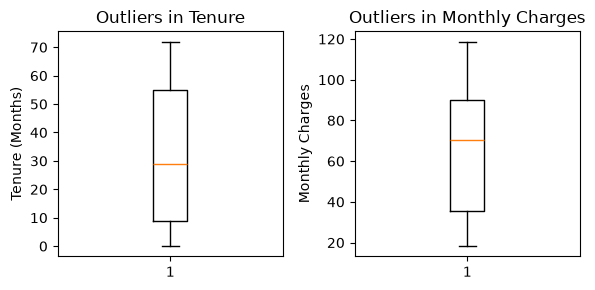

In [10]:
import matplotlib.pyplot as plt

plt.figure(figsize=(6, 3))

plt.subplot(1, 2, 1)
plt.boxplot(df['tenure'].dropna())
plt.title('Outliers in Tenure')
plt.ylabel('Tenure (Months)')

plt.subplot(1, 2, 2)
plt.boxplot(df['MonthlyCharges'].dropna())
plt.title('Outliers in Monthly Charges')
plt.ylabel('Monthly Charges')

plt.tight_layout()
plt.show()

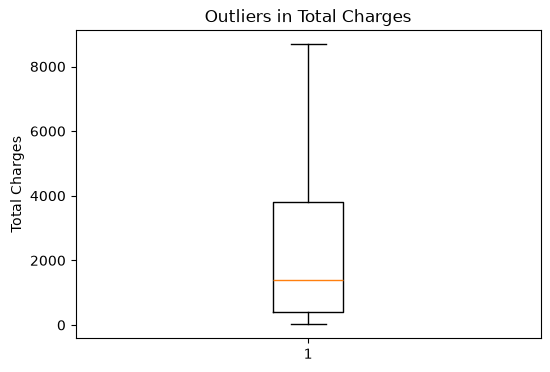

In [11]:
plt.figure(figsize=(6, 4))

plt.boxplot(df['TotalCharges'].dropna())

plt.title('Outliers in Total Charges')
plt.ylabel('Total Charges')

plt.show()

In [12]:
# Identify outliers using the IQR method
for col in ['tenure', 'MonthlyCharges', 'TotalCharges']:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1

    lower_limit = Q1 - 1.5 * IQR
    upper_limit = Q3 + 1.5 * IQR

    outliers = df[(df[col] < lower_limit) | (df[col] > upper_limit)]

    print(col, "- Number of outliers:", len(outliers))

tenure - Number of outliers: 0
MonthlyCharges - Number of outliers: 0
TotalCharges - Number of outliers: 0


In [13]:
# Group customers based on tenure
df['TenureGroup'] = pd.cut(
    df['tenure'],
    bins=[-1, 12, 36, float('inf')],
    labels=['New', 'Medium-term', 'Long-term']
)

# Calculate average monthly spending
df['AvgMonthlySpend'] = np.where(
    df['tenure'] > 0,
    df['TotalCharges'] / df['tenure'],
    0
)

print("New features created successfully!")
display(df[['tenure', 'TotalCharges', 'TenureGroup', 'AvgMonthlySpend']].head(10))

New features created successfully!


,tenure,TotalCharges,TenureGroup,AvgMonthlySpend
0,1,29.85,New,29.850000
1,34,1889.50,Medium-term,55.573529
2,2,108.15,New,54.075000
3,45,1840.75,Long-term,40.905556
4,2,151.65,New,75.825000
5,8,820.50,New,102.562500
6,22,1949.40,Medium-term,88.609091
7,10,301.90,New,30.190000
8,28,3046.05,Medium-term,108.787500
9,62,3487.95,Long-term,56.257258


In [14]:
from sklearn.preprocessing import MinMaxScaler

scaler = MinMaxScaler()

scale_cols = ['tenure', 'MonthlyCharges', 'TotalCharges']

df[['tenure_scaled', 'MonthlyCharges_scaled', 'TotalCharges_scaled']] = (
    scaler.fit_transform(df[scale_cols])
)

print("Data scaling completed successfully!")

display(df[
    ['tenure', 'tenure_scaled',
     'MonthlyCharges', 'MonthlyCharges_scaled',
     'TotalCharges', 'TotalCharges_scaled']
].head())

Data scaling completed successfully!


,tenure,tenure_scaled,MonthlyCharges,MonthlyCharges_scaled,TotalCharges,TotalCharges_scaled
0,1,0.013889,29.85,0.115423,29.85,0.001275
1,34,0.472222,56.95,0.385075,1889.50,0.215867
2,2,0.027778,53.85,0.354229,108.15,0.010310
3,45,0.625000,42.30,0.239303,1840.75,0.210241
4,2,0.027778,70.70,0.521891,151.65,0.015330


In [15]:
from sklearn.model_selection import train_test_split

# Separate input features and target
X = df.drop(columns=['Churn', 'customerID'])
y = df['Churn'].map({'No': 0, 'Yes': 1})

# Split the data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training Features Shape:", X_train.shape)
print("Testing Features Shape:", X_test.shape)
print("Training Target Shape:", y_train.shape)
print("Testing Target Shape:", y_test.shape)

Training Features Shape: (5634, 24)
Testing Features Shape: (1409, 24)
Training Target Shape: (5634,)
Testing Target Shape: (1409,)


In [16]:
df.to_csv('Telecom_Customer_Churn_Cleaned.csv', index=False)

print("Cleaned dataset exported successfully!")
print("File Name: Telecom_Customer_Churn_Cleaned.csv")
print("Final Dataset Shape:", df.shape)

Cleaned dataset exported successfully!
File Name: Telecom_Customer_Churn_Cleaned.csv
Final Dataset Shape: (7043, 26)
